# Sistem Rekomendasi Film - Collaborative Filtering

Proyek data kecil: membangun rekomendasi film dari dataset publik MovieLens 100K
(100.836 rating, 610 pengguna, 9.742 film).

**Pertanyaan:**
1. Pola rating di dataset ini seperti apa?
2. Seberapa akurat rating bisa diprediksi dari pola pengguna lain (collaborative filtering)?
3. Rekomendasi nyata untuk satu pengguna contoh seperti apa?

Dataset: https://files.grouplens.org/datasets/movielens/ml-latest-small.zip

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ratings = pd.read_csv('data/ml-latest-small/ratings.csv')
movies = pd.read_csv('data/ml-latest-small/movies.csv')
df = ratings.merge(movies, on='movieId')
print('ratings:', ratings.shape, '| users:', ratings.userId.nunique(), '| movies:', ratings.movieId.nunique())
df.head()

ratings: (100836, 4) | users: 610 | movies: 9724


,userId,movieId,rating,timestamp,title,genres
0,1,1,4.0,964982703,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,1,3,4.0,964981247,Grumpier Old Men (1995),Comedy|Romance
2,1,6,4.0,964982224,Heat (1995),Action|Crime|Thriller
3,1,47,5.0,964983815,Seven (a.k.a. Se7en) (1995),Mystery|Thriller
4,1,50,5.0,964982931,"Usual Suspects, The (1995)",Crime|Mystery|Thriller


## 1. Eksplorasi

Tiga hal dasar: sebaran nilai rating, film yang paling banyak dirating,
dan seberapa kosong matriks user x film (sparsity) - ini yang bikin rekomendasi jadi masalah menarik.

In [2]:
print('rata-rata rating: {:.2f}'.format(df.rating.mean()))
print()
counts = df.groupby('title').rating.agg(['count', 'mean'])
print('10 film paling banyak dirating:')
print(counts.sort_values('count', ascending=False).head(10).round(2))
print()
print('film dengan rata-rata tertinggi (minimal 50 rating):')
print(counts[counts['count'] >= 50].sort_values('mean', ascending=False).head(5).round(2))
print()
n_users, n_movies = ratings.userId.nunique(), ratings.movieId.nunique()
sparsity = 1 - len(ratings) / (n_users * n_movies)
print(f'sparsity matriks user x film: {sparsity:.1%} kosong')

rata-rata rating: 3.50

10 film paling banyak dirating:
                                           count  mean
title                                                 
Forrest Gump (1994)                          329  4.16
Shawshank Redemption, The (1994)             317  4.43
Pulp Fiction (1994)                          307  4.20
Silence of the Lambs, The (1991)             279  4.16
Matrix, The (1999)                           278  4.19
Star Wars: Episode IV - A New Hope (1977)    251  4.23
Jurassic Park (1993)                         238  3.75
Braveheart (1995)                            237  4.03
Terminator 2: Judgment Day (1991)            224  3.97
Schindler's List (1993)                      220  4.22

film dengan rata-rata tertinggi (minimal 50 rating):
                                                    count  mean
title                                                          
Shawshank Redemption, The (1994)                      317  4.43
Godfather, The (1972)                 

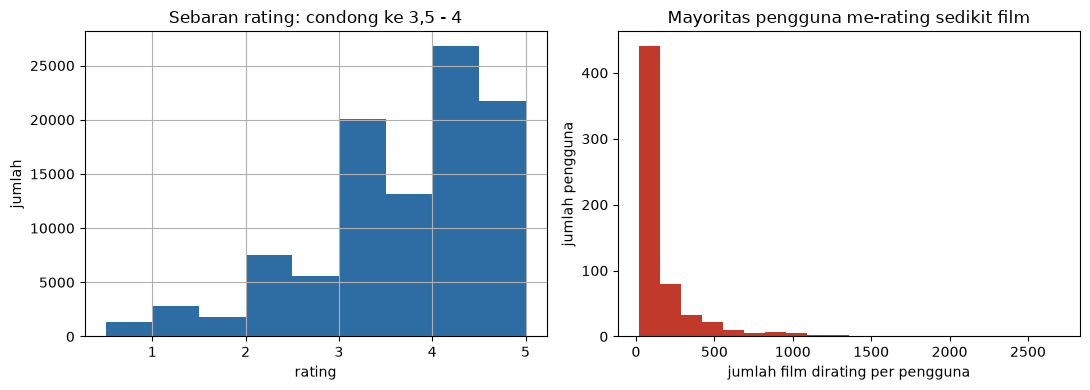

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df.rating.hist(bins=9, ax=axes[0], color='#2e6da4')
axes[0].set_xlabel('rating')
axes[0].set_ylabel('jumlah')
axes[0].set_title('Sebaran rating: condong ke 3,5 - 4')

per_user = ratings.groupby('userId').size()
axes[1].hist(per_user, bins=20, color='#c0392b')
axes[1].set_xlabel('jumlah film dirating per pengguna')
axes[1].set_ylabel('jumlah pengguna')
axes[1].set_title('Mayoritas pengguna me-rating sedikit film')
plt.tight_layout()
plt.show()

## 2. Baseline dulu

Sebelum model pintar-pintaran, ukur dulu cara paling bodoh:
- **Global mean**: semua rating diprediksi = rata-rata keseluruhan.
- **Rata-rata per film**: rating diprediksi = rata-rata film itu di data latih.

Metriknya RMSE (akar kuadrat rata-rata error kuadrat) di data uji yang sama.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

train, test = train_test_split(ratings, test_size=0.2, random_state=42)

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

global_mean = train.rating.mean()
item_mean = train.groupby('movieId').rating.mean()

pred_global = np.full(len(test), global_mean)
pred_item = test.movieId.map(item_mean).fillna(global_mean)

print(f'RMSE global mean : {rmse(test.rating, pred_global):.3f}')
print(f'RMSE rata-rata film: {rmse(test.rating, pred_item):.3f}')

RMSE global mean : 1.049
RMSE rata-rata film: 0.983


## 3. Item-based collaborative filtering

Idenya: dua film dianggap mirip kalau pola rating penggunanya mirip
(cosine similarity antar kolom film di matriks user x film).
Prediksi rating seorang pengguna untuk satu film = rata-rata tertimbang
rating yang dia berikan ke film-film lain, diboboti kemiripannya dengan film target.

In [5]:
from sklearn.metrics.pairwise import cosine_similarity

matrix = train.pivot_table(index='userId', columns='movieId', values='rating')
movie_ids = matrix.columns.to_numpy()
user_ids = matrix.index.to_numpy()
filled = matrix.fillna(0).to_numpy()

sim = cosine_similarity(filled.T)
print('matriks film x film:', sim.shape)

movie_pos = {m: i for i, m in enumerate(movie_ids)}
user_pos = {u: i for i, u in enumerate(user_ids)}
user_ratings = matrix.to_numpy()  # NaN = belum dirating

def predict(user, movie, k=20):
    if user not in user_pos or movie not in movie_pos:
        return np.nan
    u = user_pos[user]
    j = movie_pos[movie]
    rated = ~np.isnan(user_ratings[u])
    if rated.sum() == 0:
        return np.nan
    sims = sim[j].copy()
    sims[j] = 0
    sims[~rated] = 0
    top = np.argsort(sims)[::-1][:k]
    top = top[sims[top] > 0]
    if len(top) == 0:
        return np.nan
    return float(np.dot(sims[top], user_ratings[u][top]) / sims[top].sum())

preds, trues = [], []
for row in test.itertuples():
    p = predict(row.userId, row.movieId)
    if not np.isnan(p):
        preds.append(p)
        trues.append(row.rating)

print(f'pasangan uji yang bisa diprediksi: {len(preds)} dari {len(test)}')
print(f'RMSE item-based CF: {rmse(np.array(trues), np.array(preds)):.3f}')

matriks film x film: (8983, 8983)


pasangan uji yang bisa diprediksi: 19351 dari 20168
RMSE item-based CF: 0.861


## 4. Rekomendasi nyata

Dua contoh keluaran sistem: film yang dianggap mirip dengan satu film terkenal,
dan 10 rekomendasi teratas untuk satu pengguna contoh.

Catatan penting: rekomendasi naif dari CF mentah ternyata jelek - film-film
sangat langka yang kebetulan mirip dengan satu-dua film favorit pengguna
mendapat skor sempurna 5,00 dan menguasai daftar. Itu artefak data tipis,
bukan rekomendasi beneran. Jadi daftar rekomendasi di bawah memakai tiga rem:
film harus punya minimal 30 rating di data latih, prediksi harus didukung
minimal 5 film tetangga, dan skornya ditarik (shrinkage) ke rata-rata film itu
sebanding lemahnya dukungan.

In [6]:
title_of = movies.set_index('movieId').title.to_dict()

def similar_movies(title_fragment, n=5):
    match = movies[movies.title.str.contains(title_fragment, case=False, regex=False)]
    mid = match.iloc[0].movieId
    j = movie_pos[mid]
    order = np.argsort(sim[j])[::-1]
    out = []
    for i in order:
        if movie_ids[i] != mid:
            out.append((title_of[movie_ids[i]], round(float(sim[j][i]), 3)))
        if len(out) == n:
            break
    return match.iloc[0].title, out

base, sims = similar_movies('Toy Story')
print('film acuan:', base)
for t, s in sims:
    print(f'  {s:.3f}  {t}')

film acuan: Toy Story (1995)
  0.469  Back to the Future (1985)
  0.463  Lion King, The (1994)
  0.460  Shawshank Redemption, The (1994)
  0.458  Star Wars: Episode VI - Return of the Jedi (1983)
  0.457  Forrest Gump (1994)


In [7]:
def predict_dengan_dukungan(user, movie, k=20):
    u, j = user_pos[user], movie_pos[movie]
    rated = ~np.isnan(user_ratings[u])
    sims = sim[j].copy()
    sims[j] = 0
    sims[~rated] = 0
    top = np.argsort(sims)[::-1][:k]
    top = top[sims[top] > 0]
    if len(top) == 0:
        return np.nan, 0, 0.0
    w = float(sims[top].sum())
    return float(np.dot(sims[top], user_ratings[u][top]) / w), len(top), w

item_mean_all = train.groupby('movieId').rating.mean()
item_count_all = train.groupby('movieId').rating.count()

def recommend(user, n=10):
    seen = set(train.loc[train.userId == user, 'movieId'])
    scored = []
    for m in movie_ids:
        m = int(m)
        if m in seen or item_count_all.get(m, 0) < 30:
            continue
        p, n_nb, w = predict_dengan_dukungan(user, m)
        if np.isnan(p) or n_nb < 5:
            continue
        adj = (w * p + 2.0 * item_mean_all[m]) / (w + 2.0)
        scored.append((title_of[m], adj))
    return sorted(scored, key=lambda x: -x[1])[:n]

contoh_user = 1
print(f'10 film yang sudah dirating tertinggi oleh user {contoh_user}:')
top_seen = (train[train.userId == contoh_user].merge(movies, on='movieId')
            .sort_values('rating', ascending=False).head(10))
print(top_seen[['title', 'rating']].to_string(index=False))
print()
print(f'rekomendasi untuk user {contoh_user}:')
for t, s in recommend(contoh_user):
    print(f'  {s:.2f}  {t}')

10 film yang sudah dirating tertinggi oleh user 1:
                        title  rating
         Rescuers, The (1977)     5.0
    Thin Red Line, The (1998)     5.0
   Secret of NIMH, The (1982)     5.0
            Spaceballs (1987)     5.0
           Thunderball (1965)     5.0
                 Shaft (1971)     5.0
   Black Cauldron, The (1985)     5.0
NeverEnding Story, The (1984)     5.0
                Dr. No (1962)     5.0
 From Russia with Love (1963)     5.0

rekomendasi untuk user 1:


  4.66  Howl's Moving Castle (Hauru no ugoku shiro) (2004)
  4.65  Hot Fuzz (2007)
  4.65  Kiss Kiss Bang Bang (2005)
  4.63  Dark Knight Rises, The (2012)
  4.62  Ferris Bueller's Day Off (1986)
  4.62  V for Vendetta (2006)
  4.61  Raiders of the Lost Ark (Indiana Jones and the Raiders of the Lost Ark) (1981)
  4.61  Producers, The (1968)
  4.61  Departed, The (2006)
  4.61  Scott Pilgrim vs. the World (2010)


## 5. Kesimpulan

1. **Item-based CF mengalahkan baseline** - RMSE-nya lebih rendah dari sekadar menebak rata-rata film, jadi pola "pengguna yang suka X juga suka Y" memang membawa sinyal nyata.
2. **Sparsity adalah musuh utama**: 98%+ matriks kosong, dan sebagian pasangan uji tidak bisa diprediksi karena filmnya tidak punya tetangga yang cukup. Di sistem produksi ini ditangani dengan fallback (rata-rata film / film populer).
3. Pelajaran paling berharga justru dari kegagalan pertama: rekomendasi CF naif dikuasai film langka berskor 5,00 palsu. Setelah ditambah syarat dukungan minimum dan shrinkage, daftar untuk pengguna contoh jadi masuk akal - ada film animasi (selera dia memang animasi klasik), laga-petualangan, dan komedi yang sejalan dengan rating 5 yang dia berikan.
4. Pengembangan lanjutan yang wajar: matrix factorization (SVD) untuk menangkap faktor laten, dan evaluasi ranking (Precision@K) selain RMSE.